In [1]:
import ase
import numpy as np
import pyscf
from pyscf import gto, dft
import time
from ase.data import atomic_numbers, chemical_symbols

In [2]:
mol = gto.M(atom='O  0  0  0.1184; H  0,  0.7532, -0.4735; H 0,  -0.7532, -0.4735 ', basis='def2svp')
mf = dft.RKS(mol)
mf.chkfile=False
mf.xc = 'pbe'
mf.kernel()
print('num_primary', mol.bas_nprim(0))
print('num contracted', mol.bas_nctr(0))
print('basis exponents', mol.bas_exp(0))
print('kappa', mol.bas_kappa(0))
print('contaction coeffs', mol.bas_ctr_coeff(0))
print('env', mol._env)
print('bas', mol._bas)
print('atm', mol._atm)
print('basis', mol._basis)
print('len env', len(mol._env))
print('mo_coeff', mf.mo_coeff)
print('mo_occ', mf.mo_occ)
print('etot', mf.e_tot)

converged SCF energy = -76.2720603883278
num_primary 5
num contracted 1
basis exponents [2266.1767785   340.87010191   77.36313517   21.47964494    6.65894331]
kappa 0
contaction coeffs [[-0.00538935]
 [-0.04023472]
 [-0.18008184]
 [-0.46828858]
 [-0.44692617]]
env [ 1.37036000e+02  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  2.23743573e-01  0.00000000e+00
  0.00000000e+00  1.42334172e+00 -8.94785320e-01  0.00000000e+00
  0.00000000e+00 -1.42334172e+00 -8.94785320e-01  0.00000000e+00
  1.30107010e+01  1.96225720e+00  4.44537960e-01  5.79558311e-01
  9.83185649e-01  1.11930512e+00  1.21949620e-01  5.21375192e-01
  8.00000000e-01  2.20722637e+00  2.26617678e+03  3.40870102e+02
  7.73631352e+01  2

In [3]:
data = np.load('datasets/h2o_dynamic_ham_def2svp_201_dft_f.npy', allow_pickle=True).item()
print('keys', data.keys())
hamiltonians = data['full_hamiltonian']
overlaps = data['overlap_matrix']
print(hamiltonians.shape)

keys dict_keys(['positions', 'energy', 'forces', 'full_hamiltonian', 'overlap_matrix', 'core_hamiltonian', 'atom_types', 'atom_numbers'])
(4999, 24, 24)


In [4]:
import scipy as sp
orbital_coeffs = []
for i in range(hamiltonians.shape[0]):
    en, coefs = sp.linalg.eigh(a=hamiltonians[i], b=overlaps[i])
    occ_orbitals = en > 0
    orbital_coeffs.append(coefs)

In [5]:
orbital_data = np.load('datasets/h2o_dynamic_pyscf_dft_f_en.npy', allow_pickle=True)

energies_ccp = []
for orb in orbital_data:
    print(orb[1]['mo_coeff'].shape)
    energies_ccp.append(orb[1]['energy'])
    
energies_ccp = np.array(energies_ccp)

(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(

(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(58, 58)
(

In [6]:
orbital_data = np.load('datasets/h2o_dynamic_pyscf_631gss_dft_f.npy', allow_pickle=True)

energies_631gss = []
for orb in orbital_data:
    print(orb[1]['mo_coeff'].shape)
    energies_631gss.append(orb[1]['energy'])
    
energies_631gss = np.array(energies_631gss)

(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(

(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(24, 24)
(

In [7]:
print(energies_631gss)
print(energies_ccp)
print(np.corrcoef(energies_631gss, energies_ccp))
print('energy diff', (energies_631gss - np.mean(energies_631gss) + np.mean(energies_ccp)) - energies_ccp)
print(np.mean(np.abs((energies_631gss - np.mean(energies_631gss) + np.mean(energies_ccp)) - energies_ccp)))

[-76.29950042 -76.29783259 -76.29867207 ... -76.29305686 -76.30242746
 -76.31676137]
[-76.34226192 -76.33943037 -76.33947341 ... -76.33691874 -76.34458357
 -76.35868938]
[[1.         0.99873729]
 [0.99873729 1.        ]]
energy diff [ 9.01583965e-04 -2.62141210e-04 -1.05858651e-03 ...  2.00195941e-03
  2.96187755e-04  6.80874792e-05]
0.0007771291494587879


In [8]:
print(orbital_coeffs[0][0])
print(orbital_data[0][1]['mo_coeff'][0])


[ 9.88437198e-01 -2.71872472e-01 -2.59515686e-02 -1.21934764e-01
 -4.43761991e-07 -9.70533860e-02 -3.32429148e-02  4.18710465e-02
  9.46969071e-02 -2.34792096e-04 -1.62760783e-01 -8.69431262e-02
 -2.12501504e-01  9.83859801e-02 -1.63784147e-06  2.36240482e-06
  2.77602507e-03 -8.31370612e-02  1.19658847e-01  7.27569742e-07
 -2.39530171e-06  2.17312669e-02 -6.47139291e-02 -6.93631566e-02]
[ 9.94808341e-01 -2.07392181e-01  1.94493088e-02 -9.15945360e-02
 -6.48338010e-09  7.98352206e-02  3.56905161e-02 -5.83853757e-03
  5.80197684e-03  2.18694168e-08 -7.08572078e-02 -3.81354889e-02
  4.83547503e-02  1.13709047e-02  6.96765699e-08  3.19184234e-08
  1.17821378e-02 -3.53745918e-03 -3.02240913e-07  3.07438075e-02
  1.32350855e-07  5.04243835e-03 -7.71707365e-02  3.21794835e-02]


In [9]:
for i in range(len(orbital_data)):
    #print(mfs[i].mo_coeff
    orbital_data[i][1]['mo_coeff'] = orbital_coeffs[i]
    orbital_data[i][1]['mo_occ'] = mf.mo_occ
    orbital_data[i][0]['basis'] = 'def2svp'
np.save('datasets/h2o_dynamic_pyscf_def2svp_ham_dft_f.npy', orbital_data, allow_pickle=True)

In [10]:
from equiv_dens.data.density_dataset import AtomsDensityData
from functools import partial
from equiv_dens.utils.grids import cubical_grid, cubical_sampling, CubicalGrid
import torch

cube_grid_fn = partial(cubical_grid, nx=50, ny=50, nz=50,
                       extent=np.array([4.1483, 4.1483, 4.1483]),
                       origin=np.array([-2.0318, -2.0318 , -2.0318]))
cube_sampling_fn = cubical_sampling

cube_dataset_631gss = AtomsDensityData(np_path='datasets/h2o_dynamic_def2svp_no_ham.npy', density_path='datasets/h2o_dynamic_def2svp_pyscf_format.npy',
                                      orbitals_path='datasets/augccpvqzjkfit_orbital_basis_df.npy',
                                      density_n_samp=10000000000,
                                      required_properties=['density'],
                                      center_positions=False,
                                      radial_coeffs_file='datasets/augccpvqzjkfit_radial_coeffs_df.npy',
                                      dtype=torch.float,
                                      grid_fn=cube_grid_fn,
                                      sampling_fn=cube_sampling_fn)

cube_dataset_ccpvdz = AtomsDensityData(np_path='datasets/h2o_dynamic_centered.npy', density_path='datasets/h2o_dynamic_pyscf_def2svp_ham_dft_f.npy',
                                      orbitals_path='datasets/augccpvqzjkfit_orbital_basis_df.npy',
                                      density_n_samp=10000000000,
                                      required_properties=['density'],
                                      center_positions=False,
                                      radial_coeffs_file='datasets/augccpvqzjkfit_radial_coeffs_df.npy',
                                      dtype=torch.float,
                                      grid_fn=cube_grid_fn,
                                      sampling_fn=cube_sampling_fn)

Use "numpy" for Fourier Transform
Starting atomsdata density init
Some variables
atoms keys dict_keys(['positions', 'energy', 'forces', 'atom_types', 'atom_numbers', 'orbitals'])
mol_dict [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.7667551 , -0.27679202, -0.65606403], dtype=float32)), ('H', array([ 0.22926103,  0.6861921 , -0.40823704], dtype=float32))]
finished init
Starting atomsdata density init
Some variables
atoms keys dict_keys(['positions', 'energy', 'forces', 'full_hamiltonian', 'overlap_matrix', 'core_hamiltonian', 'atom_types', 'atom_numbers'])
mol_dict [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.766755, -0.276792, -0.656064], dtype=float32)), ('H', array([ 0.229261  ,  0.68619204, -0.40823698], dtype=float32))]
finished init


<IPython.core.display.Javascript object>


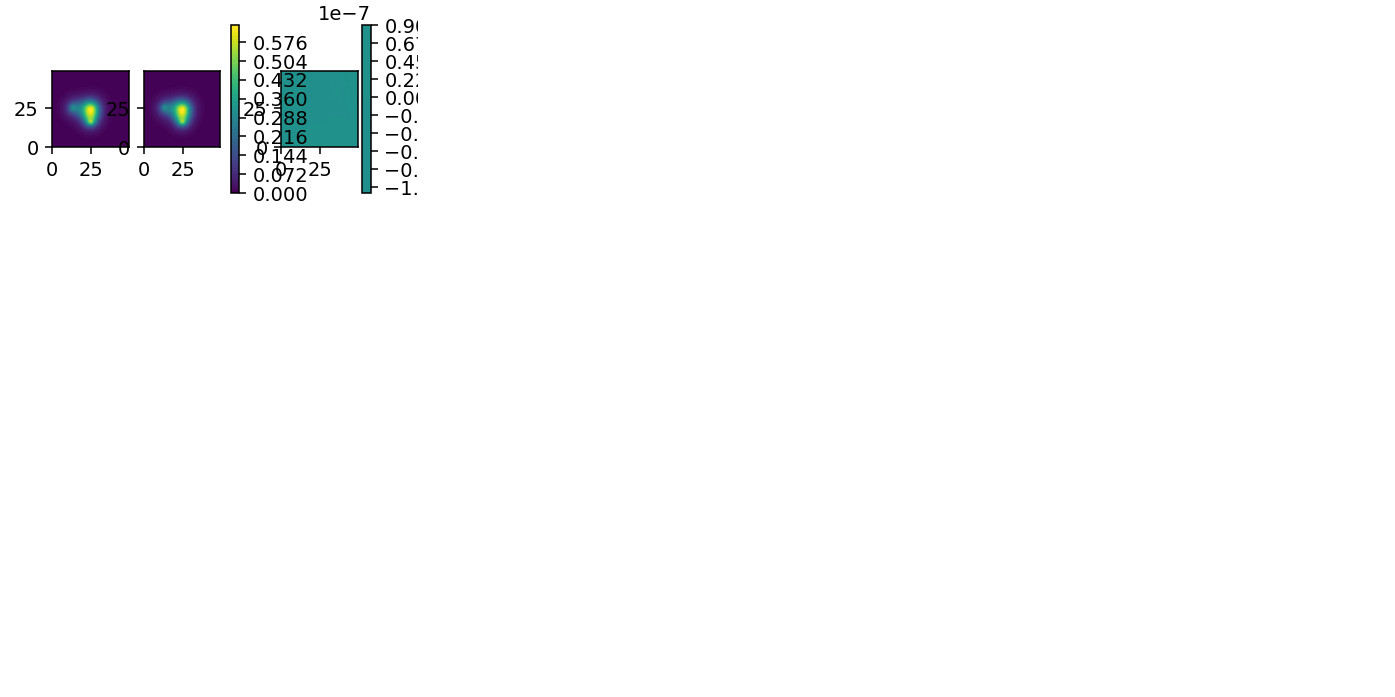

idx [    19   2519   5019 ... 119969 122469 124969]
pos tensor([[[ 0.0000,  0.0000,  0.0000],
         [-0.9271,  0.1267, -0.5001],
         [ 0.0622, -0.6538, -0.4586]]])
dens shape (125000,)
dens shape (125000,)
pos tensor([[[ 0.0000,  0.0000,  0.0000],
         [-0.9271,  0.1267, -0.5001],
         [ 0.0622, -0.6538, -0.4586]]])


In [11]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
%matplotlib notebook
%load_ext autoreload
%autoreload 2

sample = 5
fig = plt.figure(figsize=(10, 5))


x, y  = np.meshgrid(np.arange(50), np.arange(50))
x_f = x.flatten()
y_f = y.flatten()
z_f = np.zeros_like(y_f) + 19
idx = np.ravel_multi_index((x_f, y_f, z_f), (50, 50, 50))
                
#X, Y, Z = np.meshgrid(np.arange(50) + 38, np.arange(50) + 38, np.arange(50) + 38)
#X = X.flatten()
#Y = Y.flatten()
#Z = Z.flatten()
#ndices = np.ravel_multi_index((X, Y, Z), (125, 125, 125))


ax1 = fig.add_subplot(131)
print('idx', idx)
dens = np.array(cube_dataset_ccpvdz[sample]['density'].squeeze())
print('pos', cube_dataset_ccpvdz[sample]['positions'])
print('dens shape', dens.shape)
dens2d_ccp = dens[idx]
dens2d_ccp = dens2d_ccp.reshape(50, 50)
vmin = np.min(dens2d_ccp)
vmax = np.max(dens2d_ccp)
c1 = ax1.contourf(x, y, dens2d_ccp, vmin=vmin, vmax=vmax, levels=100)
ax1.set_aspect('equal')

ax2 = fig.add_subplot(132)
dens = np.array(cube_dataset_631gss[sample]['density'].squeeze())
print('dens shape', dens.shape)
print('pos', cube_dataset_631gss[sample]['positions'])
dens2d_631 = dens[idx]
dens2d_631 = dens2d_631.reshape(50, 50)
c2 = ax2.contourf(x, y, dens2d_631, vmin=vmin, vmax=vmax, levels=100)
ax2.set_aspect('equal')

ax3 = fig.add_subplot(133)
c3 = ax3.contourf(x, y, dens2d_631 - dens2d_ccp, vmin=-0.1, vmax=0.1, levels=100)
ax3.set_aspect('equal')


fig.colorbar(c2, ax=[ax1, ax2])
fig.colorbar(c3, ax=[ax3])
#plt.savefig('figures/target_vs_pred_dens.pdf', dpi=300)
plt.show()

In [ ]:
ccpvdz_sample = cube_dataset_ccpvdz[sample]
gss631_sample = cube_dataset_631gss[sample]
print('ccpvdz integral', torch.sum(ccpvdz_sample['density'] * ccpvdz_sample['coord_weights']))
print('631gss integral', torch.sum(gss631_sample['density'] * gss631_sample['coord_weights']))
print('error pct', torch.sum(torch.abs(gss631_sample['density'] - ccpvdz_sample['density']) * gss631_sample['coord_weights']))
print(ccpvdz_sample['density'][0, 62450:62550])
print(gss631_sample['density'][0, 62450:62550])
print(torch.abs(gss631_sample['density'] - ccpvdz_sample['density'])[0, 62450:62550])

print(torch.max(ccpvdz_sample['density']))
print(torch.max(gss631_sample['density']))
print(torch.max(torch.abs(gss631_sample['density'] - ccpvdz_sample['density'])))

In [15]:
from pyscf import lib
mo_coeff = orbital_coeffs[0]
mo_occ = mf.mo_occ
h1e = mf.get_hcore(mol)
dm = mf.make_rdm1(mo_coeff, mo_occ)
        # attach mo_coeff and mo_occ to dm to improve DFT get_veff efficiency
dm = lib.tag_array(dm, mo_coeff=mo_coeff, mo_occ=mo_occ)
vhf = mf.get_veff(mol, dm)
e_tot = mf.energy_tot(dm, h1e, vhf)
print(e_tot)

-74.49662370218807


In [16]:
print(energies.shape)
print(data['energy'].shape)
print('corr', np.corrcoef(energies, -data['energy'].squeeze()))
print('mae', np.mean(np.abs(energies + data['energy'].squeeze())))

print(energies)
print(data['energy'].squeeze())

NameError: name 'energies' is not defined

In [17]:
cube_dataset_ccpvdz.mols[0].cart

False

In [18]:
orb_631gss = np.load('datasets/h2o_dynamic_pyscf_631gss_dft_f.npy', allow_pickle=True)
orb_def2svp= np.load('datasets/h2o_dynamic_pyscf_def2svp_dft_f.npy', allow_pickle=True)
orb_631gss_ham = np.load('datasets/h2o_dynamic_pyscf_631gss_ham_dft_f.npy', allow_pickle=True)
orb_def2svp_ham = np.load('datasets/h2o_dynamic_pyscf_def2svp_ham_dft_f.npy', allow_pickle=True)
orb_631gss_ham_old = np.load('datasets/h2o_dynamic_pyscf_631gss_ham_dft_f_en.npy', allow_pickle=True)

In [19]:
print('631gss', orb_631gss[0][1]['energy'])
print('def2svp', orb_def2svp[0][1]['energy'])
print('def2svp ham', orb_def2svp_ham[0][1]['mo_coeff'][0])
print('631gss ham', orb_631gss_ham[0][1]['mo_coeff'][0])
print('631gss ham old', orb_631gss_ham_old[0][1]['mo_coeff'][0])

631gss -76.2995004166075
def2svp -76.24074581373364
def2svp ham [ 9.88437198e-01 -2.71872472e-01 -2.59515686e-02 -1.21934764e-01
 -4.43761991e-07 -9.70533860e-02 -3.32429148e-02  4.18710465e-02
  9.46969071e-02 -2.34792096e-04 -1.62760783e-01 -8.69431262e-02
 -2.12501504e-01  9.83859801e-02 -1.63784147e-06  2.36240482e-06
  2.77602507e-03 -8.31370612e-02  1.19658847e-01  7.27569742e-07
 -2.39530171e-06  2.17312669e-02 -6.47139291e-02 -6.93631566e-02]
631gss ham [ 9.8843747e-01  2.7187237e-01  2.5951635e-02  1.2193479e-01
 -5.1288208e-07 -9.7053431e-02  3.3242863e-02  4.1871078e-02
  9.4696596e-02 -2.1718806e-04  1.6276111e-01  8.6943425e-02
 -2.1250114e-01 -9.8385744e-02  1.5627623e-06  2.4220919e-06
 -2.7761315e-03 -8.3137155e-02 -1.1965891e-01  6.6252193e-07
  2.3911716e-06 -2.1731257e-02 -6.4714178e-02  6.9363251e-02]
631gss ham old [ 9.8843747e-01  2.7187237e-01  2.5951635e-02  1.2193479e-01
 -5.1288208e-07 -9.7053431e-02  3.3242863e-02  4.1871078e-02
  9.4696596e-02 -2.1718806e-04

In [20]:
npy_dat_old = np.load('datasets/h2o_dynamic_centered.npy', allow_pickle=True).item()
npy_dat_new = np.load('datasets/h2o_dynamic_def2svp_no_ham.npy', allow_pickle=True).item()


print('old_pos', npy_dat_old['positions'])
print('new_pos', npy_dat_new['positions'])
print(np.all(np.isclose(npy_dat_old['positions'], npy_dat_new['positions'])))
print('old keys', npy_dat_old.keys())
print('new_keys', npy_dat_new.keys())

old_pos [[[ 0.          0.          0.        ]
  [-0.766755   -0.276792   -0.656064  ]
  [ 0.229261    0.68619204 -0.40823698]]

 [[ 0.          0.          0.        ]
  [ 0.626068   -0.515363   -0.883514  ]
  [ 0.530928    0.554313    0.57312596]]

 [[ 0.          0.          0.        ]
  [ 0.15871398  1.018463   -0.028846  ]
  [-1.028616    0.46100196  0.06952199]]

 ...

 [[ 0.          0.          0.        ]
  [ 0.53840005  0.19933799 -0.6019989 ]
  [-0.69757897 -0.548543   -0.075269  ]]

 [[ 0.          0.          0.        ]
  [-0.22698799  1.086965    0.03207099]
  [ 0.11792699 -0.56160396 -0.835961  ]]

 [[ 0.          0.          0.        ]
  [ 0.84488094  0.444754   -0.36528298]
  [-0.64638996 -0.530823   -0.606611  ]]]
new_pos [[[ 0.          0.          0.        ]
  [-0.7667551  -0.27679202 -0.65606403]
  [ 0.22926103  0.6861921  -0.40823704]]

 [[ 0.          0.          0.        ]
  [ 0.6260681  -0.515363   -0.88351405]
  [ 0.530928    0.55431306  0.573126  ]]

 [

In [21]:
calc_dat_old = np.load('datasets/h2o_dynamic_pyscf_def2svp_ham_dft_f.npy', allow_pickle=True)
calc_dat_new = np.load('datasets/h2o_dynamic_def2svp_pyscf_format.npy', allow_pickle=True)

for i in range(len(calc_dat_old)):
    print('i', i)
    print('old atom', calc_dat_old[i][0])
    print('new atom', calc_dat_new[i][0])

i 0
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.766755, -0.276792, -0.656064], dtype=float32)), ('H', array([ 0.229261  ,  0.68619204, -0.40823698], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.7667551 , -0.27679202, -0.65606403], dtype=float32)), ('H', array([ 0.22926103,  0.6861921 , -0.40823704], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 1
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([ 0.626068, -0.515363, -0.883514], dtype=float32)), ('H', array([0.530928  , 0.554313  , 0.57312596], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, '

old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([ 0.701491  ,  0.457595  , -0.26423696], dtype=float32)), ('H', array([ 0.54988796, -0.17662299,  0.618292  ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([ 0.70149106,  0.45759502, -0.26423702], dtype=float32)), ('H', array([ 0.549888  , -0.17662302,  0.61829203], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 187
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([0.774069  , 0.39776295, 0.54281896], dtype=float32)), ('H', array([-0.157824  , -0.69313097,  0.697854  ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry'

new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.49399105, -0.44933602, -0.61173403], dtype=float32)), ('H', array([ 0.29697603, -0.58642906,  0.76248604], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 365
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-1.0920899 , -0.004153  , -0.19007598], dtype=float32)), ('H', array([-0.479202  , -0.38234898,  0.82638997], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-1.09209   , -0.004153  , -0.19007601], dtype=float32)), ('H', array([-0.47920203, -0.382349  ,  0.82639   ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmet

new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([ 0.93649805, -0.55047005,  0.21975102], dtype=float32)), ('H', array([ 0.29608604,  1.0258731 , -0.14987001], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 535
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.9299639 , -0.112931  ,  0.35318294], dtype=float32)), ('H', array([0.32784498, 0.14385399, 0.9142589 ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.929964  , -0.11293101,  0.353183  ], dtype=float32)), ('H', array([0.327845 , 0.143854 , 0.9142591], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': Fals

new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.6280821 , -0.41563106, -0.79454905], dtype=float32)), ('H', array([ 0.8206711 , -0.77398604, -0.28656703], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 714
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([ 0.7109069 , -0.004817  , -0.62983996], dtype=float32)), ('H', array([ 0.011649  , -0.42210597,  0.8145629 ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([ 0.71090704, -0.004817  , -0.6298401 ], dtype=float32)), ('H', array([ 0.011649  , -0.42210603,  0.81456304], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmet

new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([ 0.85998005, -0.07733701, -0.64005303], dtype=float32)), ('H', array([ 0.55798805, -0.548932  ,  0.7570891 ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 883
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.655052  , -0.77195895, -0.39245996], dtype=float32)), ('H', array([ 0.774048  , -0.40941897,  0.101231  ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.65505207, -0.77195907, -0.39246   ], dtype=float32)), ('H', array([ 0.7740481 , -0.40941903,  0.10123101], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmet

... (19 outputs left out)

new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.9132511 ,  0.42115203, -0.07286701], dtype=float32)), ('H', array([ 0.93043107, -0.139614  , -0.63354903], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 4319
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.92650795,  0.061413  , -0.169959  ], dtype=float32)), ('H', array([ 0.199431, -0.909654, -0.049235], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.92650807,  0.06141301, -0.169959  ], dtype=float32)), ('H', array([ 0.19943102, -0.9096541 , -0.049235  ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': 

new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.68670803, -0.45853505,  0.592773  ], dtype=float32)), ('H', array([-0.09189901,  0.92866004,  0.10856801], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 4484
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.56497097, -0.097264  , -0.73683894], dtype=float32)), ('H', array([ 0.177757  , -1.0516909 , -0.12840499], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.564971  , -0.09726401, -0.736839  ], dtype=float32)), ('H', array([ 0.17775701, -1.051691  , -0.128405  ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symme

new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.22183102, -0.86279106,  0.265675  ], dtype=float32)), ('H', array([ 0.81265604,  0.35145202, -0.12155001], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 4665
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.48671997,  0.7775859 , -0.325968  ], dtype=float32)), ('H', array([-0.345315 ,  0.259164 ,  0.9602849], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.48672003,  0.77758604, -0.32596803], dtype=float32)), ('H', array([-0.34531504,  0.259164  ,  0.96028507], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry

new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([-0.82207406, -0.13358101, -0.47301003], dtype=float32)), ('H', array([-0.35172403,  0.527674  ,  0.831003  ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
i 4841
old atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([0.921201  , 0.15137099, 0.047152  ], dtype=float32)), ('H', array([ 0.19638598, -0.91226697,  0.069969  ], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': False, 'nucmod': {}, 'nucprop': {}, 'ecp': {}, '_nelectron': None, 'verbose': 3}
new atom {'atom': [('O', array([0., 0., 0.], dtype=float32)), ('H', array([0.9212011 , 0.151371  , 0.04715201], dtype=float32)), ('H', array([ 0.19638601, -0.9122671 ,  0.06996901], dtype=float32))], 'unit': 'angstrom', 'basis': 'def2svp', 'charge': 0, 'spin': 0, 'symmetry': 

In [22]:
from equiv_dens.data.density_dataset import AtomsDensityData
from functools import partial
from equiv_dens.utils.grids import cubical_grid, cubical_sampling, CubicalGrid
import torch

cube_grid_fn = partial(cubical_grid, nx=50, ny=50, nz=50,
                       extent=2*np.array([4.1483, 4.1483, 4.1483]),
                       origin=2*np.array([-2.0318, -2.0318 , -2.0318]))
cube_sampling_fn = cubical_sampling

cube_dataset_def2svp = AtomsDensityData(np_path='datasets/ethanol_def2svp_no_ham.npy', density_path='datasets/ethanol_def2svp_pyscf_format.npy',
                                      orbitals_path='datasets/augccpvqzjkfit_orbital_basis_df.npy',
                                      density_n_samp=10000000000,
                                      required_properties=['density'],
                                      center_positions=False,
                                      radial_coeffs_file='datasets/augccpvqzjkfit_radial_coeffs_df.npy',
                                      dtype=torch.float,
                                      grid_fn=cube_grid_fn,
                                      sampling_fn=cube_sampling_fn)


Starting atomsdata density init
Some variables
atoms keys dict_keys(['positions', 'energy', 'forces', 'atom_types', 'atom_numbers', 'orbitals'])
mol_dict [('C', array([-0.334921  , -0.48401302, -0.122297  ], dtype=float32)), ('C', array([-0.9672121 ,  0.75899607,  0.71944207], dtype=float32)), ('O', array([ 1.1647551 , -0.30509505, -0.52487403], dtype=float32)), ('H', array([-0.178957  , -1.4295661 ,  0.44627503], dtype=float32)), ('H', array([-0.87473005, -0.660305  , -1.167093  ], dtype=float32)), ('H', array([-1.9156421 ,  0.54569507,  1.0775571 ], dtype=float32)), ('H', array([-0.17022702,  0.87315106,  1.4867241 ], dtype=float32)), ('H', array([-0.9022831 ,  1.6611001 ,  0.24397701], dtype=float32)), ('H', array([ 1.070602  ,  0.5757921 , -0.87202305], dtype=float32))]
finished init


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<IPython.core.display.Javascript object>


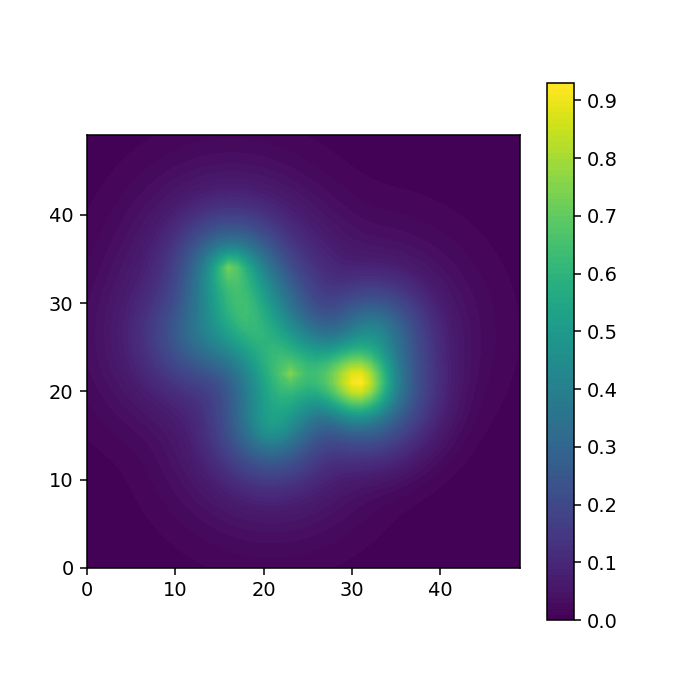

idx [    25   2525   5025 ... 119975 122475 124975]
pos tensor([[[-0.1545, -0.3352,  0.4690],
         [-1.0499,  0.7724, -0.2272],
         [ 1.0837, -0.4611, -0.1966],
         [ 0.0275, -0.0955,  1.5707],
         [-0.5523, -1.3848,  0.5494],
         [-1.3235,  1.6866,  0.1754],
         [-0.4528,  1.0753, -1.1170],
         [-2.0118,  0.3536, -0.6461],
         [ 1.4633,  0.4734, -0.2939]]])
dens shape (125000,)


In [24]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
%matplotlib notebook
%load_ext autoreload
%autoreload 2

sample = 5
def2svp_sample = cube_dataset_def2svp[sample]
fig = plt.figure(figsize=(5, 5))


x, y  = np.meshgrid(np.arange(50), np.arange(50))
x_f = x.flatten()
y_f = y.flatten()
z_f = np.zeros_like(y_f) + 25
idx = np.ravel_multi_index((x_f, y_f, z_f), (50, 50, 50))
                
#X, Y, Z = np.meshgrid(np.arange(50) + 38, np.arange(50) + 38, np.arange(50) + 38)
#X = X.flatten()
#Y = Y.flatten()
#Z = Z.flatten()
#ndices = np.ravel_multi_index((X, Y, Z), (125, 125, 125))


ax1 = fig.add_subplot(111)
print('idx', idx)
dens = np.array(def2svp_sample['density'].squeeze())
print('pos', def2svp_sample['positions'])
print('dens shape', dens.shape)
dens2d_ccp = dens[idx]
dens2d_ccp = (dens2d_ccp.reshape(50, 50))**(1/3)
vmin = np.min(dens2d_ccp)
vmax = np.max(dens2d_ccp)
c1 = ax1.contourf(x, y, dens2d_ccp, vmin=vmin, vmax=vmax, levels=100)
ax1.set_aspect('equal')

fig.colorbar(c1, ax=ax1)
#plt.savefig('figures/target_vs_pred_dens.pdf', dpi=300)
plt.show()

In [25]:
print('def2svp integral', torch.sum(def2svp_sample['density'] * def2svp_sample['coord_weights']))

def2svp integral tensor(24.4706)


In [32]:
print(cube_dataset_def2svp.coeffs[5])

{'mo_coeff': array([[ 1.22735447e-04,  9.87765993e-01, -1.85511137e-03, ...,
        -2.73632672e-02,  4.49242719e-02, -1.70665571e-02],
       [-9.18604862e-04,  5.04326022e-02,  1.89777474e-03, ...,
         2.43878852e-01, -1.64575099e-01,  4.06299319e-02],
       [ 1.88733866e-02, -3.58914517e-02, -1.05351903e-02, ...,
         1.13664986e-01, -8.46419289e-01,  1.38368631e-01],
       ...,
       [ 6.89934507e-04, -1.03834447e-03,  2.42264861e-04, ...,
        -2.38903757e-01,  1.60910017e-03,  3.89081766e-01],
       [ 2.66448835e-03, -1.15251418e-05, -1.27506509e-04, ...,
         9.17087024e-02,  3.74689815e-01,  9.30826103e-01],
       [-1.19435063e-04,  6.61829268e-04, -5.81125976e-05, ...,
         1.72051910e-01,  3.45493530e-02, -9.60314849e-02]]), 'mo_occ': array([2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.